In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds


# ---------------- Models ----------------

class MostPopular:
    """Global top-K by purchase frequency in training data."""
    def __init__(self, k=10):
        self.k = k
        self.items_ = None

    def fit(self, df, user_col, item_col, time_col=None):
        counts = Counter(df[item_col])
        self.items_ = [i for i, _ in counts.most_common(self.k)]
        return self

    def recommend(self, users):
        return {u: list(self.items_) for u in users}


class RecentPopular:
    """Top-K by frequency in the most recent `window` fraction of training data."""
    def __init__(self, k=10, window=0.2):
        self.k = k
        self.window = window
        self.items_ = None

    def fit(self, df, user_col, item_col, time_col=None):
        d = df.sort_values(time_col)
        recent = d.tail(max(1, int(len(d) * self.window)))
        counts = Counter(recent[item_col])
        self.items_ = [i for i, _ in counts.most_common(self.k)]
        return self

    def recommend(self, users):
        return {u: list(self.items_) for u in users}


class SVDRecommender:
    """Truncated SVD on the binary user-item matrix."""
    def __init__(self, k=10, latent_dim=50, exclude_seen=True):
        self.k = k
        self.latent_dim = latent_dim
        self.exclude_seen = exclude_seen

    def fit(self, df, user_col, item_col, time_col=None):
        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        data = np.ones(len(df), dtype=np.float32)
        mat = csr_matrix((data, (rows, cols)), shape=(len(users), len(items)))
        self.seen_ = mat

        k = min(self.latent_dim, min(mat.shape) - 1)
        if k < 1:
            self.user_factors_ = np.zeros((len(users), 0), np.float32)
            self.item_factors_ = np.zeros((len(items), 0), np.float32)
            return self
        U, s, Vt = svds(mat, k=k)
        order = np.argsort(-s)
        U, s, Vt = U[:, order], s[order], Vt[order]
        self.user_factors_ = (U * s).astype(np.float32)
        self.item_factors_ = Vt.T.astype(np.float32)
        return self

    def recommend(self, users):
        recs = {}
        pop = np.asarray(self.seen_.sum(axis=0)).ravel()
        pop_top = [self.items_[i] for i in np.argsort(-pop)[: self.k]]

        for u in users:
            u_str = str(u)
            if u_str not in self.user_idx_ or self.item_factors_.shape[1] == 0:
                recs[u] = list(pop_top)
                continue
            ui = self.user_idx_[u_str]
            scores = (self.user_factors_[ui] @ self.item_factors_.T).ravel()
            if self.exclude_seen:
                scores[self.seen_[ui].indices] = -np.inf
            kk = min(self.k, scores.size)
            if kk == 0:
                recs[u] = []; continue
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top]
        return recs

class ItemKNN:
    def __init__(self, k=10, n_neighbors=200):
        self.k = k
        self.n_neighbors = n_neighbors

    def fit(self, df, user_col, item_col, time_col=None):
        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        X = csr_matrix((np.ones(len(df), np.float32), (rows, cols)),
                       shape=(len(users), len(items)))
        X.data = np.ones_like(X.data)
        self.seen_ = X

        norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=0)).ravel()) + 1e-9
        Xn = X.multiply(1.0 / norms).tocsr()

        # sparse cosine item-item similarity — never densified
        S = (Xn.T @ Xn).tocsr()
        S.setdiag(0.0)
        S.eliminate_zeros()

        # per-row top-n_neighbors pruning directly on csr buffers
        n_nb = min(self.n_neighbors, S.shape[0] - 1)
        if n_nb > 0 and S.nnz > 0:
            data, indices, indptr = S.data, S.indices, S.indptr
            new_data    = np.empty(data.size, dtype=data.dtype)
            new_indices = np.empty(indices.size, dtype=indices.dtype)
            new_indptr  = np.zeros(indptr.size, dtype=indptr.dtype)
            pos = 0
            for i in range(S.shape[0]):
                s, e = indptr[i], indptr[i + 1]
                rd, ri = data[s:e], indices[s:e]
                if rd.size > n_nb:
                    keep = np.argpartition(-rd, n_nb - 1)[:n_nb]
                    rd, ri = rd[keep], ri[keep]
                n = rd.size
                new_data[pos:pos + n]    = rd
                new_indices[pos:pos + n] = ri
                pos += n
                new_indptr[i + 1] = pos
            S = csr_matrix((new_data[:pos], new_indices[:pos], new_indptr),
                           shape=S.shape)
        self.S_ = S
        self.pop_ = np.asarray(X.sum(axis=0)).ravel()
        return self

    def recommend(self, users):
        pop_top = [self.items_[i] for i in np.argsort(-self.pop_)[: self.k]]
        recs = {}
        for u in users:
            ui = self.user_idx_.get(str(u))
            if ui is None:
                recs[u] = list(pop_top); continue
            # sparse @ sparse -> sparse; densify only the 1 x n_items result
            scores = (self.seen_[ui] @ self.S_).toarray().ravel()
            kk = min(self.k, scores.size)
            if kk == 0:
                recs[u] = list(pop_top); continue
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top]
        return recs

class EASE:
    """EASE restricted to top-max_items by popularity (dense inverse is O(N^2) memory)."""
    def __init__(self, k=10, l2=200.0, max_items=20_000, min_item_count=5):
        self.k = k
        self.l2 = l2
        self.max_items = max_items
        self.min_item_count = min_item_count

    def fit(self, df, user_col, item_col, time_col=None):
        counts = df[item_col].value_counts()
        counts = counts[counts >= self.min_item_count]
        if counts.size > self.max_items:
            counts = counts.iloc[: self.max_items]
        kept = set(counts.index)
        df = df[df[item_col].isin(kept)]
        if len(df) == 0:
            raise ValueError("No items survived the EASE candidate filter.")

        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        X = csr_matrix((np.ones(len(df), np.float32), (rows, cols)),
                       shape=(len(users), len(items)))
        X.data = np.ones_like(X.data)
        self.seen_ = X
        self.pop_ = np.asarray(X.sum(axis=0)).ravel()

        G = (X.T @ X).toarray().astype(np.float64)
        G[np.diag_indices(G.shape[0])] += self.l2
        P = np.linalg.inv(G)
        B = -P / np.diag(P)[None, :]
        np.fill_diagonal(B, 0.0)
        self.B_ = B.astype(np.float32)
        return self

    def recommend(self, users):
        Xt = self.seen_.T.tocsr()
        pop_top = [self.items_[i] for i in np.argsort(-self.pop_)[: self.k]]
        recs = {}
        for u in users:
            ui = self.user_idx_.get(str(u))
            if ui is None:
                recs[u] = list(pop_top); continue
            scores = np.asarray((Xt[:, ui].T @ self.B_)).ravel()
            kk = min(self.k, scores.size)
            if kk == 0:
                recs[u] = list(pop_top); continue
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top]
        return recs
        
class EmbeddingAvg:
    def __init__(self, k=10, dim=64, min_count=1):
        self.k = k
        self.dim = dim
        self.min_count = min_count

    def fit(self, df, user_col, item_col, time_col=None):
        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)
        n_users, n_items = len(users), len(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        X = csr_matrix((np.ones(len(df), np.float32), (rows, cols)),
                       shape=(n_users, n_items))
        X.data = np.ones_like(X.data)          # binarize
        self.seen_ = X
        self.pop_ = np.asarray(X.sum(axis=0)).ravel()

        # sparse co-occurrence — never densified
        C = (X.T @ X).tocsr().astype(np.float64)
        C.setdiag(0.0)
        C.eliminate_zeros()

        # PPMI on the non-zero entries only
        C = C.tocoo()
        row_sum = np.asarray(C.sum(axis=1)).ravel()
        col_sum = np.asarray(C.sum(axis=0)).ravel()
        total   = C.data.sum() + 1e-9
        with np.errstate(divide="ignore", invalid="ignore"):
            pmi = np.log(C.data * total /
                         (row_sum[C.row] * col_sum[C.col] + 1e-9))
        pmi = np.nan_to_num(pmi, nan=0.0, posinf=0.0, neginf=0.0)
        mask = pmi > 0
        P = csr_matrix((pmi[mask], (C.row[mask], C.col[mask])), shape=C.shape)

        # truncated SVD on sparse PPMI
        d = min(self.dim, min(P.shape) - 1)
        if d < 1 or P.nnz == 0:
            E = np.zeros((n_items, 1), np.float32)
        else:
            U, s, Vt = svds(P, k=d)          # scipy accepts sparse
            order = np.argsort(-s)
            E = (Vt[order].T * np.sqrt(np.maximum(s[order], 0.0))[None, :]
                 ).astype(np.float32)
        self.item_emb_  = E
        self.item_emb_n_ = (E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
                            ).astype(np.float32)
        return self

    def recommend(self, users):
        pop_top = [self.items_[i] for i in np.argsort(-self.pop_)[: self.k]]
        recs = {}
        for u in users:
            ui = self.user_idx_.get(str(u))
            if ui is None:
                recs[u] = list(pop_top); continue
            idxs = self.seen_[ui].indices
            if idxs.size == 0:
                recs[u] = list(pop_top); continue

            uprof = self.item_emb_n_[idxs].mean(axis=0)
            uprof = uprof / (np.linalg.norm(uprof) + 1e-9)

            scores = self.item_emb_n_ @ uprof
            scores[idxs] = -np.inf

            kk = min(self.k, scores.size)
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top if np.isfinite(scores[i])]
        return recs

class ItemTimeBase:
    """Item embeddings from a low-rank factorization A @ B of the time-item purchase matrix."""
    def __init__(self, k=10, inner_dim=50, segment_length="1M",
                 appearance_only=False, exclude_seen=True):
        self.k = k
        self.inner_dim = inner_dim
        self.segment_length = segment_length
        self.appearance_only = appearance_only
        self.exclude_seen = exclude_seen
    


    def _segments(self, times):
        """Map timestamps to consecutive segment indices for segment_length."""
        if isinstance(self.segment_length, str):
            try:
                delta = pd.to_timedelta(self.segment_length)
            except (ValueError, TypeError):
                delta = None          # calendar alias, e.g. '1M' / '1Y'
        else:
            delta = pd.to_timedelta(self.segment_length)
        if delta is not None and delta > pd.Timedelta(0):
            return np.asarray((times - times.min()) // delta, dtype=np.int64)
        per = times.dt.to_period(self.segment_length)
        return pd.factorize(per)[0].astype(np.int64)


    def fit(self, df, user_col, item_col, time_col=None):
        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)
        n_users, n_items = len(users), len(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        X = csr_matrix((np.ones(len(df), np.float32), (rows, cols)),
                       shape=(n_users, n_items))
        X.data = np.ones_like(X.data)          # binarize
        self.seen_ = X
        self.pop_ = np.asarray(X.sum(axis=0)).ravel()

        self.has_emb_ = False
        self.item_emb_ = np.zeros((n_items, 1), np.float32)
        self.item_emb_n_ = self.item_emb_
        if time_col is None or len(df) == 0:
            return self

        t = pd.to_datetime(df[time_col], errors="coerce")
        valid = t.notna().values
        if not valid.any():
            return self
        seg = np.full(len(df), -1, np.int64)
        seg[valid] = self._segments(t[valid])
        keep = seg >= 0

        seg_c = pd.factorize(seg[keep])[0]
        item_c = cols[keep]
        if seg_c.size == 0:
            return self
        n_seg = int(seg_c.max()) + 1
        if n_seg < 2:
            return self

        # sparse time-item matrix M (n_items x n_periods)
        M = csr_matrix((np.ones(item_c.size, np.float32), (item_c, seg_c)),
                       shape=(n_items, n_seg))
        M.sum_duplicates()
        if self.appearance_only:
            M.data = np.ones_like(M.data)

        d = min(self.inner_dim, min(M.shape) - 1)
        if d < 1 or M.nnz == 0:
            return self

        # best rank-d approximation A @ B of M; A is the item embedding
        U, s, Vt = svds(M, k=d)
        order = np.argsort(-s)
        A = (U[:, order] * np.sqrt(np.maximum(s[order], 0.0))[None, :]
             ).astype(np.float32)
        self.item_emb_ = A
        self.item_emb_n_ = (A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-9)
                            ).astype(np.float32)
        self.has_emb_ = True
        return self

    def recommend(self, users):
        pop_top = [self.items_[i] for i in np.argsort(-self.pop_)[: self.k]]
        recs = {}
        for u in users:
            ui = self.user_idx_.get(str(u))
            if ui is None or not self.has_emb_:
                recs[u] = list(pop_top); continue
            idxs = self.seen_[ui].indices
            if idxs.size == 0:
                recs[u] = list(pop_top); continue

            uprof = self.item_emb_n_[idxs].mean(axis=0)
            uprof = uprof / (np.linalg.norm(uprof) + 1e-9)

            scores = self.item_emb_n_ @ uprof
            if self.exclude_seen:
                scores[idxs] = -np.inf

            kk = min(self.k, scores.size)
            if kk == 0:
                recs[u] = list(pop_top); continue
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top if np.isfinite(scores[i])]
        return recs
      
# ---------------- Metrics ----------------

def precision_at_k(recs, truth, k):
    return np.mean([len(set(recs[u][:k]) & truth[u]) / k for u in truth])

def recall_at_k(recs, truth, k):
    return np.mean([len(set(recs[u][:k]) & truth[u]) / len(truth[u]) for u in truth])

def hit_rate_at_k(recs, truth, k):
    return np.mean([1.0 if set(recs[u][:k]) & truth[u] else 0.0 for u in truth])

def ndcg_at_k(recs, truth, k):
    vals = []
    for u, t in truth.items():
        t = set(t); dcg = 0.0
        for i, it in enumerate(recs[u][:k], 1):
            if it in t:
                dcg += 1 / np.log2(i + 1)
        ideal = sum(1 / np.log2(i + 1) for i in range(1, min(len(t), k) + 1))
        vals.append(dcg / ideal if ideal else 0.0)
    return np.mean(vals)


# ---------------- Comparator ----------------

class ModelComparator:
    """
    split: 'global_time' (default) | 'random' | 'per_user_time'
    """
    def __init__(self, models, k=10, split="global_time",
                 val_size=0.15, test_size=0.15, random_state=42):
        self.models = models
        self.k = k
        self.split = split
        self.val_size = val_size
        self.test_size = test_size
        self.random_state = random_state
        self.results_ = None

    def _split(self, df, user_col, time_col):
        vs, ts = self.val_size, self.test_size
        if self.split == "global_time":
            d = df.sort_values(time_col).reset_index(drop=True)
            n = len(d); n_te = int(n * ts); n_va = int(n * vs)
            return (d.iloc[:n - n_te - n_va],
                    d.iloc[n - n_te - n_va:n - n_te],
                    d.iloc[n - n_te:])
        if self.split == "random":
            d = df.sample(frac=1.0, random_state=self.random_state).reset_index(drop=True)
            n = len(d); n_te = int(n * ts); n_va = int(n * vs)
            return (d.iloc[:n - n_te - n_va],
                    d.iloc[n - n_te - n_va:n - n_te],
                    d.iloc[n - n_te:])
        if self.split == "per_user_time":
            parts = {"train": [], "val": [], "test": []}
            for _, g in df.sort_values(time_col).groupby(user_col):
                n = len(g); n_te = max(1, int(n * ts)); n_va = max(1, int(n * vs))
                if n - n_te - n_va < 1:
                    parts["train"].append(g); continue
                parts["train"].append(g.iloc[:n - n_te - n_va])
                parts["val"].append(g.iloc[n - n_te - n_va:n - n_te])
                parts["test"].append(g.iloc[n - n_te:])
            return tuple(pd.concat(parts[s]) if parts[s] else df.iloc[0:0]
                         for s in ("train", "val", "test"))
        raise ValueError(f"Unknown split: {self.split}")

    def run(self, df, user_col="Survey ResponseID",
            item_col="ASIN/ISBN (Product Code)", time_col="Order Date"):
        train, val, test = self._split(df, user_col, time_col)
        truth = test.groupby(user_col)[item_col].apply(set).to_dict()
        if not truth:
            raise RuntimeError("Empty test set after split.")

        results = {}
        for name, model in self.models.items():
            print(f"RUNNING {name}", end="")
            model.fit(train, user_col, item_col, time_col)
            recs = model.recommend(truth.keys())
            k = self.k
            results[name] = {
                f"Precision@{k}": precision_at_k(recs, truth, k),
                f"Recall@{k}":    recall_at_k(recs, truth, k),
                f"HitRate@{k}":   hit_rate_at_k(recs, truth, k),
                f"NDCG@{k}":      ndcg_at_k(recs, truth, k),
            }
            print(f" FINISHED")
        self.results_ = pd.DataFrame(results).T
        return self.results_
    
    def plot(self, figsize=(20, 16)):
        if self.results_ is None:
            raise RuntimeError("Call run() first.")

        metrics = list(self.results_.columns)
        n = len(metrics)
        ncols = 2
        nrows = int(np.ceil(n / ncols))

        palette = plt.cm.tab10(np.linspace(0, 1, len(self.results_.index)))
        color_map = dict(zip(self.results_.index, palette))

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
        axes = np.array(axes).reshape(-1)

        for ax, metric in zip(axes, metrics):
            values = self.results_[metric]
            colors = [color_map[m] for m in values.index]
            bars = ax.bar(values.index, values.values, color=colors,
                          edgecolor="black", linewidth=0.6)

            for bar, v in zip(bars, values.values):
                ax.text(bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + 0.005,
                        f"{v:.3f}", ha="center", va="bottom", fontsize=9)

            ax.set_title(metric, fontsize=12, fontweight="bold")
            ax.set_ylabel("score")
            ymax = max(0.05, values.max() * 1.2)
            ax.set_ylim(0, ymax)
            ax.grid(axis="y", linestyle="--", alpha=0.4)
            ax.set_axisbelow(True)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.tick_params(axis="x", rotation=30)
            for lbl in ax.get_xticklabels():
                lbl.set_ha("right")

        for ax in axes[len(metrics):]:
            ax.axis("off")

        fig.suptitle("Model Comparison", fontsize=14, fontweight="bold")
        fig.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

In [2]:
df = pd.read_csv("../data/Amazon1.0/amazon-purchases.csv")
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")


RUNNING ItemTimeBase FINISHED
RUNNING ItemKNN FINISHED
RUNNING EASE FINISHED
RUNNING MostPopular FINISHED
RUNNING RecentPopular FINISHED
RUNNING SVD FINISHED
RUNNING ItemEmbeddings FINISHED
                Precision@10  Recall@10  HitRate@10   NDCG@10
ItemTimeBase        0.106251   0.042056    0.582404  0.117230
ItemKNN             0.279604   0.100901    0.828247  0.300562
EASE                0.303262   0.116651    0.846348  0.340896
MostPopular         0.276679   0.107274    0.846769  0.297165
RecentPopular       0.244159   0.094552    0.827615  0.293572
SVD                 0.101389   0.037726    0.550410  0.110650
ItemEmbeddings      0.106525   0.042291    0.577563  0.114868


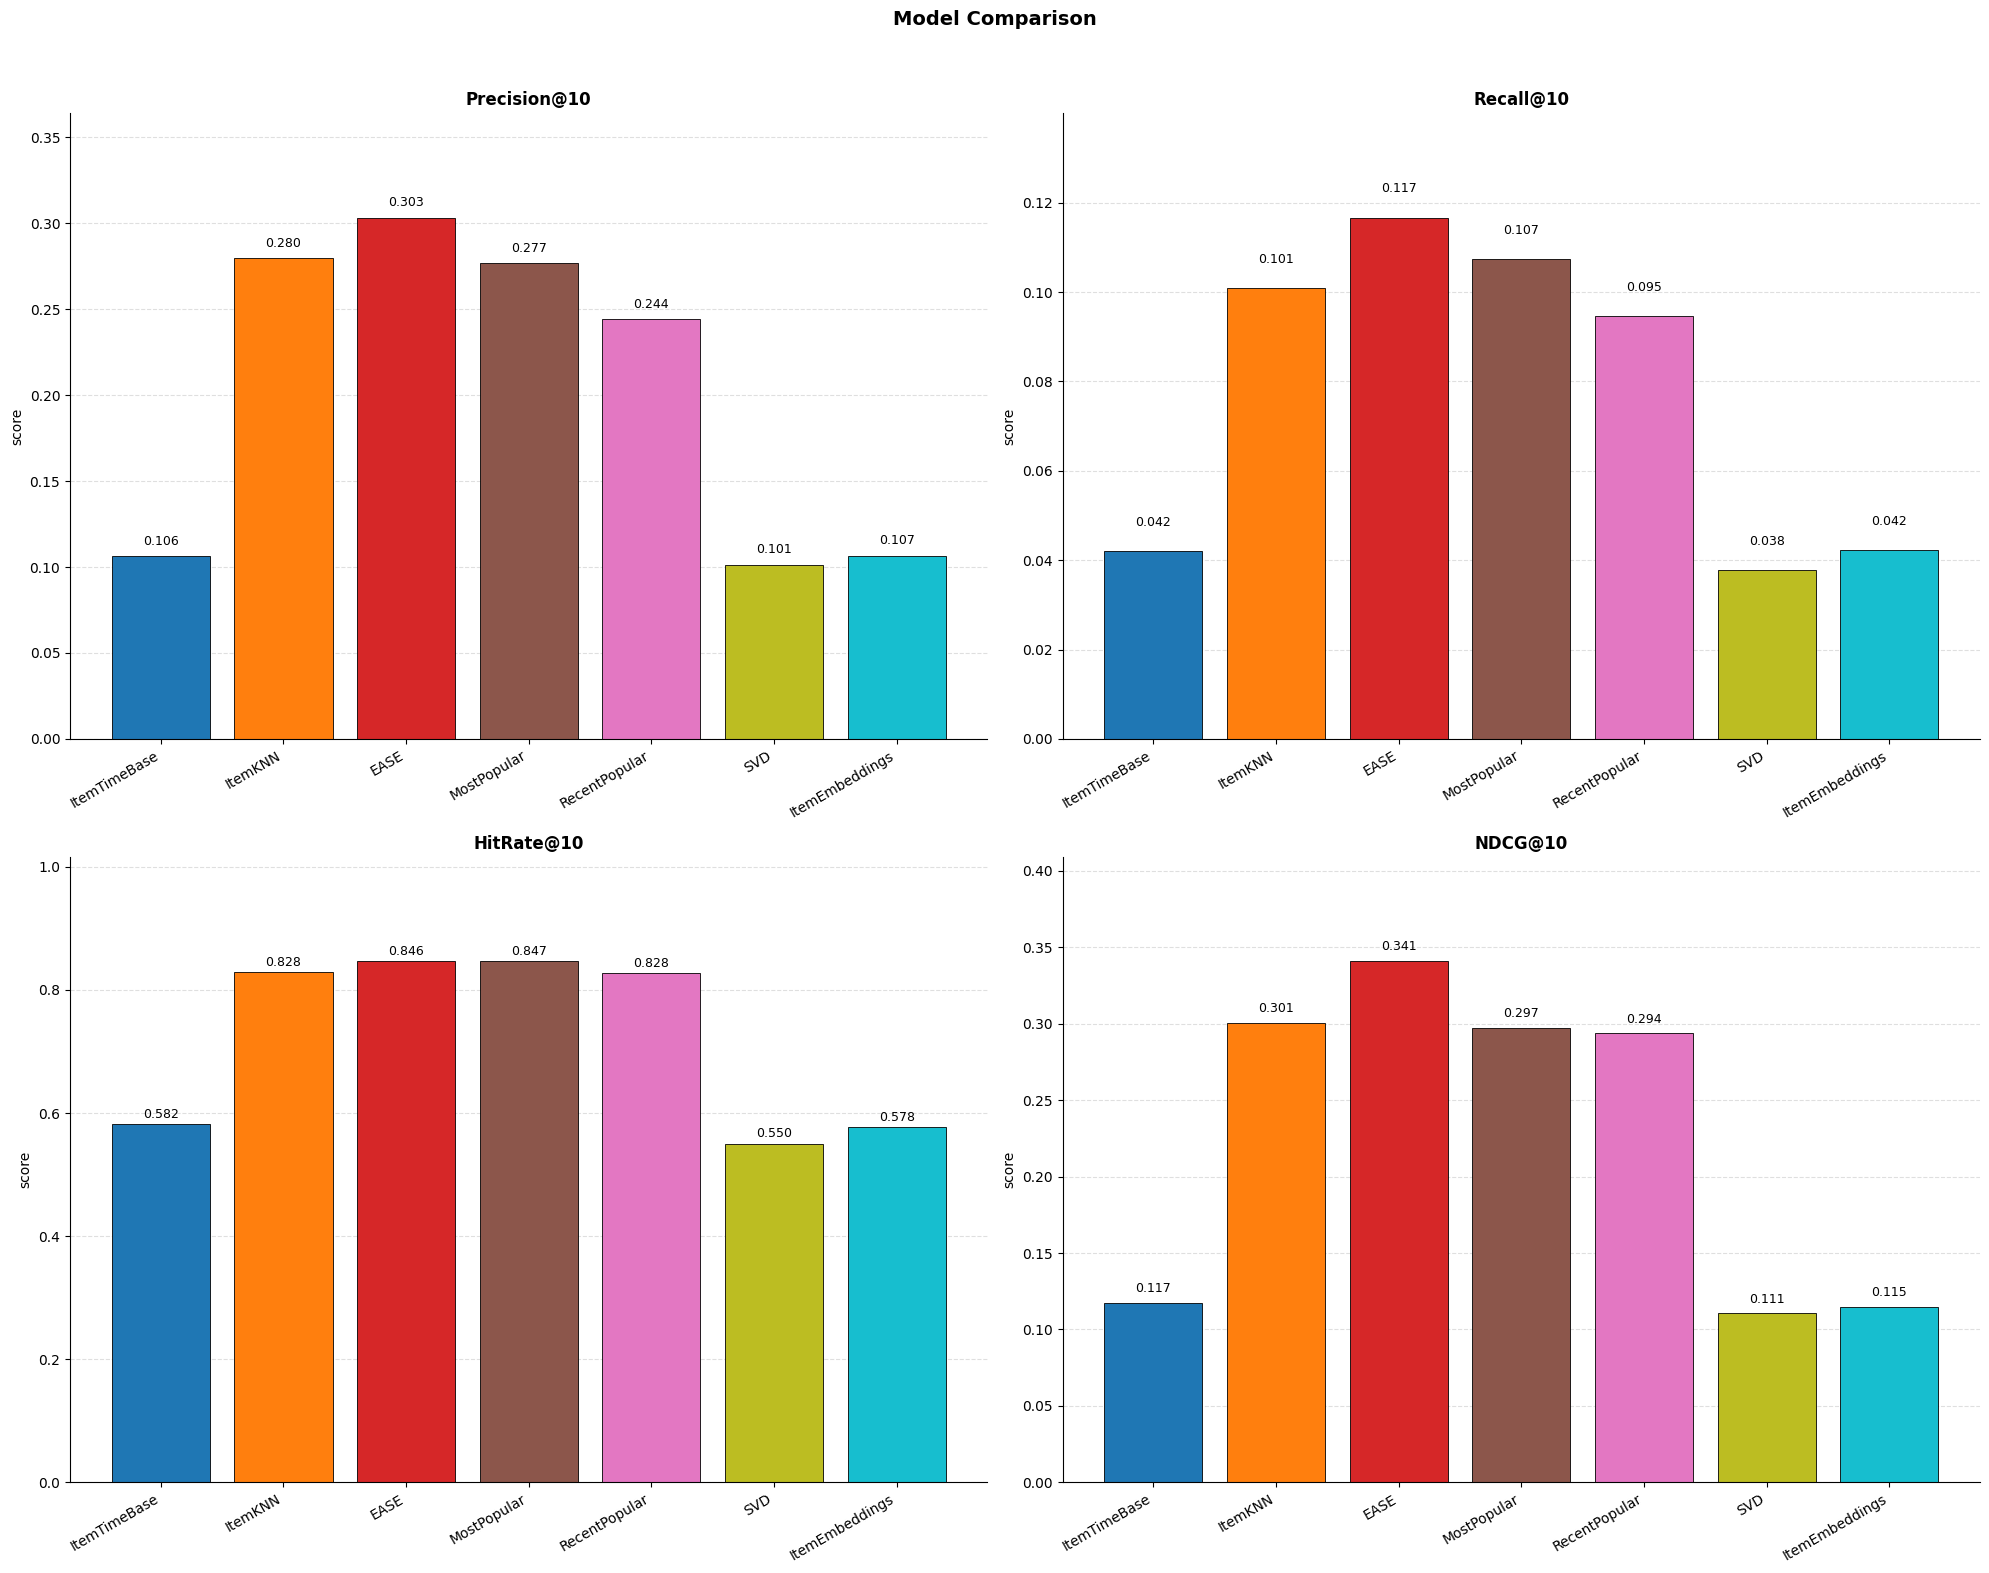

In [3]:
cmp = ModelComparator(
    models={
        "ItemTimeBase"   : ItemTimeBase(),
        "ItemKNN":         ItemKNN(k=10, n_neighbors=200),
        "EASE":            EASE(k=10, l2=200.0),
        "MostPopular":     MostPopular(k=10),
        "RecentPopular":   RecentPopular(k=10, window=0.2),
        "SVD":             SVDRecommender(k=10, latent_dim=50),
        "ItemEmbeddings" : EmbeddingAvg(),
    },
    k=10,
    split="global_time",
)
res = cmp.run(df, item_col="Category")
print(res)
cmp.plot()

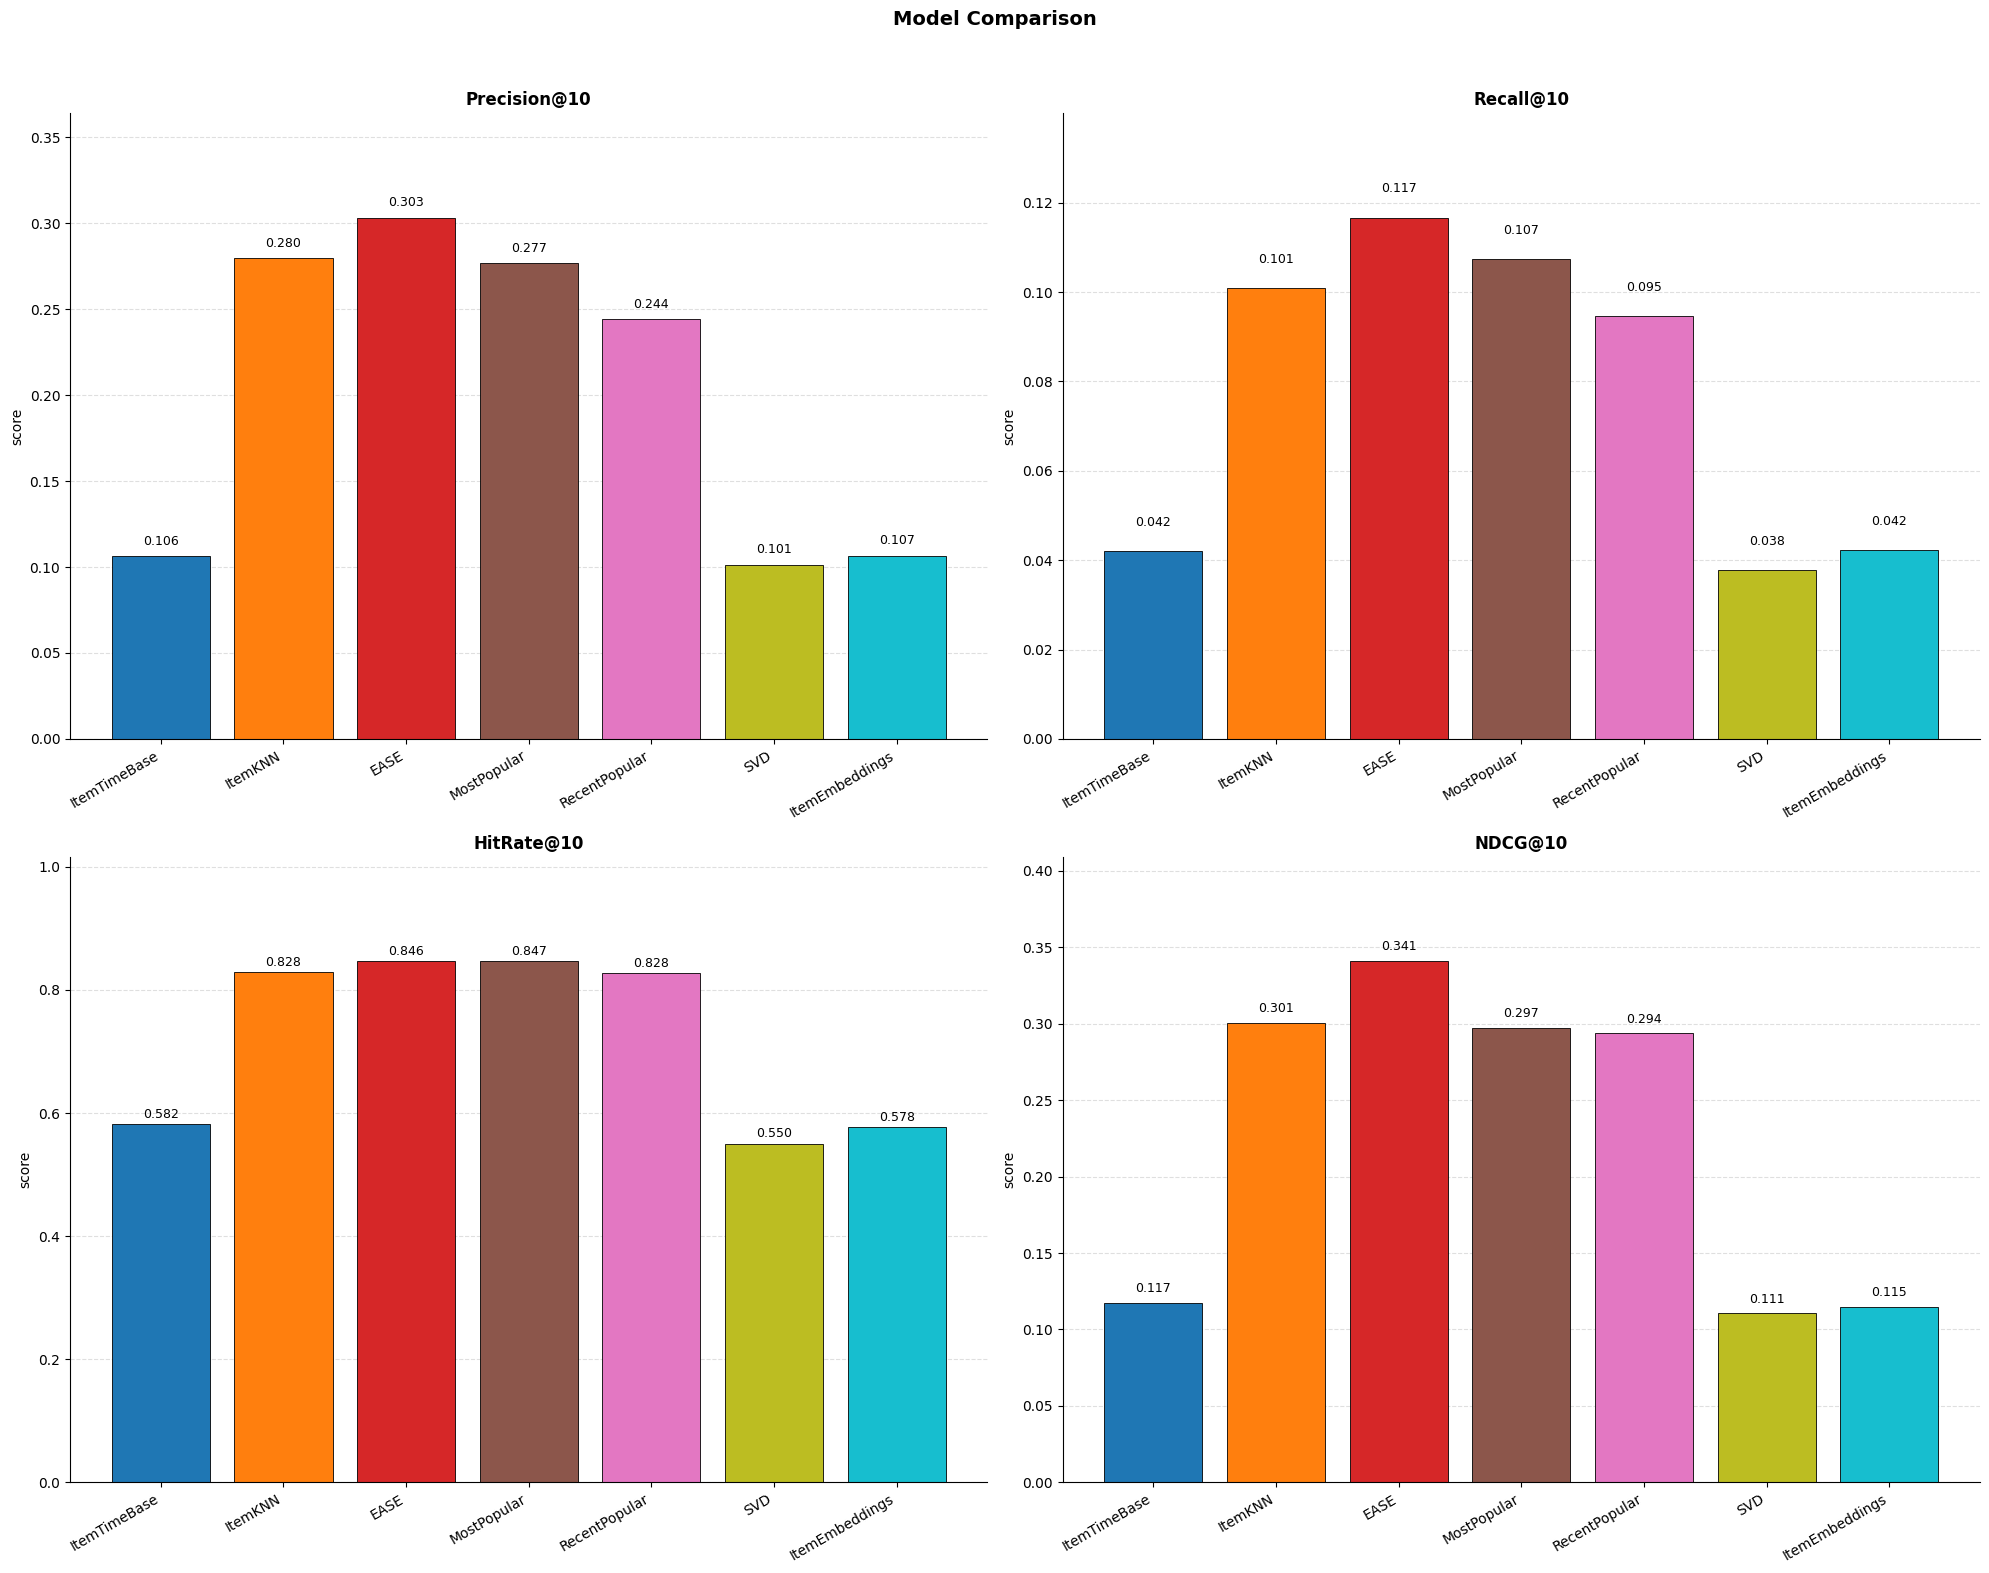

In [4]:
cmp.plot()

In [5]:
# # пока не запускаю на предсказание самих товаров, только их категории, потому что слишком большие матрицы чтобы локально поднимать их

# cmp = ModelComparator(
#     models={
#         "ItemKNN":       ItemKNN(k=10, n_neighbors=200),
#         "EASE":          EASE(k=10, l2=200.0),
#         "MostPopular":   MostPopular(k=10),
#         "RecentPopular": RecentPopular(k=10, window=0.2),
#         "SVD":           SVDRecommender(k=10, latent_dim=50),
#         "ItemEmbeddings" : EmbeddingAvg()
#     },
#     k=10,
#     split="global_time",
# )
# res = cmp.run(df)
# print(res)
# cmp.plot()

In [6]:
ItemTimeBase

__main__.ItemTimeBase